
# Machine Learning-Based Road Accident Severity Prediction

### Project Overview

This project aims to predict road accident severity in India using Machine Learning classification algorithms. It also explores the factors associated with accident severity through data analysis and feature importance.

The project uses accident data from selected Indian highways and evaluates multiple classification models to identify the most suitable approach.

**Objectives:**
- Analyze and preprocess road accident data.
- Identify patterns and factors associated with accident severity.
- Build and evaluate Machine Learning classification models.
- Compare model performance and select the best-performing model.
- Examine the limitations of accident severity prediction.


In [1]:
import sys
print(sys.executable)

c:\Users\HP User\Desktop\ML PROJECT\.venv\Scripts\python.exe


## 1. Importing Required Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

=================================================================================================================================================================================================

## 2. Loading the Dataset

In [3]:
df=pd.read_csv("ML_DataSet.csv")


### 2.1 Initial Dataset Preview

In [4]:
df.head()

,Date,Day_of_Week,Time_of_Accident,Accident_Location_A,Accident_Location_A_Chainage_km,Accident_Location_A_Chainage_km_RoadSide,Accident_Severity_C,Causes_D,Road_Feature_E,Road_Condition_F,Weather_Conditions_H,Vehicle_Type_Involved_J_V1,Vehicle_Type_Involved_J_V2
0,01-09-2013,7,13.00,2,187.6,1,3,2,2,3,8,1,NaN
1,04-09-2013,3,15.25,2,152.3,2,4,3,2,6,12,5,NaN
2,09-09-2013,1,0.40,2,177.8,1,4,3,2,6,12,5,NaN
3,11-09-2013,3,7.30,2,186.8,2,3,2,2,3,8,1,NaN
4,17-09-2013,2,13.00,2,173.4,2,4,4,3,4,7,1,NaN


### 2.2 Dataset Overview

In [5]:
df.shape
df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8116 entries, 0 to 8115
Data columns (total 13 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Date                                      8116 non-null   str    
 1   Day_of_Week                               8116 non-null   int64  
 2   Time_of_Accident                          8116 non-null   float64
 3   Accident_Location_A                       8116 non-null   int64  
 4   Accident_Location_A_Chainage_km           8116 non-null   float64
 5   Accident_Location_A_Chainage_km_RoadSide  8116 non-null   int64  
 6   Accident_Severity_C                       8116 non-null   int64  
 7   Causes_D                                  8116 non-null   int64  
 8   Road_Feature_E                            8116 non-null   int64  
 9   Road_Condition_F                          8116 non-null   int64  
 10  Weather_Conditions_H                      8116 

In [6]:
df.describe(include="all")

,Date,Day_of_Week,Time_of_Accident,Accident_Location_A,Accident_Location_A_Chainage_km,Accident_Location_A_Chainage_km_RoadSide,Accident_Severity_C,Causes_D,Road_Feature_E,Road_Condition_F,Weather_Conditions_H,Vehicle_Type_Involved_J_V1,Vehicle_Type_Involved_J_V2
count,8116,8116.000000,8116.000000,8116.000000,8116.000000,8116.000000,8116.000000,8116.000000,8116.000000,8116.000000,8116.000000,8116.000000,1962.000000
unique,1664,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,13-07-2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,4.096106,12.413526,1.864465,317.597007,1.506284,2.642188,2.544357,3.684327,1.361262,2.287087,5.416708,5.566769
std,NaN,1.989654,6.818175,0.342315,163.779091,0.499991,0.867920,0.825131,0.743114,0.987961,2.675672,3.334849,3.567214
min,NaN,1.000000,0.000000,1.000000,0.200000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,NaN,2.000000,7.000000,2.000000,185.200000,1.000000,2.000000,2.000000,4.000000,1.000000,1.000000,3.000000,3.000000
50%,NaN,4.000000,12.440000,2.000000,247.000000,2.000000,3.000000,2.000000,4.000000,1.000000,1.000000,5.000000,5.000000
75%,NaN,6.000000,18.300000,2.000000,481.200000,2.000000,3.000000,3.000000,4.000000,1.000000,2.000000,6.000000,6.000000


=================================================================================================================================================================================================

## 3. Data Quality Assessment and Cleaning

In [7]:
df.isnull().sum()

Date                                           0
Day_of_Week                                    0
Time_of_Accident                               0
Accident_Location_A                            0
Accident_Location_A_Chainage_km                0
Accident_Location_A_Chainage_km_RoadSide       0
Accident_Severity_C                            0
Causes_D                                       0
Road_Feature_E                                 0
Road_Condition_F                               0
Weather_Conditions_H                           0
Vehicle_Type_Involved_J_V1                     0
Vehicle_Type_Involved_J_V2                  6154
dtype: int64

### 3.1 Duplicate Record Analysis

Since the dataset does not contain a unique accident identifier, it cannot be confirmed whether all identical records represent accidental duplicates or separately recorded events.

In [8]:
df.duplicated().sum()

np.int64(4063)

In [9]:
df.value_counts().value_counts().sort_index()

count
2    976
4      1
6      1
Name: count, dtype: int64

In [10]:
df[df.duplicated(keep=False)].sort_values(by="Date").head(10)

,Date,Day_of_Week,Time_of_Accident,Accident_Location_A,Accident_Location_A_Chainage_km,Accident_Location_A_Chainage_km_RoadSide,Accident_Severity_C,Causes_D,Road_Feature_E,Road_Condition_F,Weather_Conditions_H,Vehicle_Type_Involved_J_V1,Vehicle_Type_Involved_J_V2
4169,01-01-2014,3,12.10,2,171.7,1,3,2,1,1,9,1,NaN
111,01-01-2014,3,12.10,2,171.7,1,3,2,1,1,9,1,NaN
5456,01-01-2015,4,8.20,1,495.9,1,3,2,4,1,1,6,NaN
5457,01-01-2015,4,17.10,1,502.0,1,3,3,4,1,1,5,NaN
1399,01-01-2015,4,17.10,1,502.0,1,3,3,4,1,1,5,NaN
388,01-01-2015,4,19.55,2,167.5,1,1,1,4,1,2,5,6.0
4446,01-01-2015,4,19.55,2,167.5,1,1,1,4,1,2,5,6.0
1398,01-01-2015,4,8.20,1,495.9,1,3,2,4,1,1,6,NaN
1900,01-01-2016,5,22.49,2,488.0,1,2,4,4,1,3,6,NaN
5958,01-01-2016,5,22.49,2,488.0,1,2,4,4,1,3,6,NaN


In [11]:
df.value_counts(dropna=False).value_counts().sort_index()

count
1       8
2    4037
4       7
6       1
Name: count, dtype: int64

In [12]:
#Dataset Size After Duplicate Removal
df.drop_duplicates().shape

(4053, 13)

In [13]:
#Removing Duplicate Records
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(4053, 13)

### 3.2 Missing Value Analysis

In [14]:
df.isnull().sum()

Date                                           0
Day_of_Week                                    0
Time_of_Accident                               0
Accident_Location_A                            0
Accident_Location_A_Chainage_km                0
Accident_Location_A_Chainage_km_RoadSide       0
Accident_Severity_C                            0
Causes_D                                       0
Road_Feature_E                                 0
Road_Condition_F                               0
Weather_Conditions_H                           0
Vehicle_Type_Involved_J_V1                     0
Vehicle_Type_Involved_J_V2                  3075
dtype: int64

In [15]:
df["Vehicle_Type_Involved_J_V2"].value_counts(dropna=False).sort_index()

Vehicle_Type_Involved_J_V2
1.0      220
2.0        6
3.0       29
4.0        3
5.0      254
6.0      239
7.0       24
8.0       28
9.0       51
10.0      16
11.0      38
12.0       3
13.0       9
14.0      33
15.0      25
NaN     3075
Name: count, dtype: int64

In [16]:
df.drop(columns=["Vehicle_Type_Involved_J_V2"], inplace=True)

C:\Users\HP User\AppData\Local\Temp\ipykernel_25348\1650775704.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["Vehicle_Type_Involved_J_V2"], inplace=True)


### 3.3 Date Format and Range Analysis

In [17]:
df["Date"].head(10)

0    01-09-2013
1    04-09-2013
2    09-09-2013
3    11-09-2013
4    17-09-2013
5    19-09-2013
6    19-09-2013
7    20-09-2013
8    26-09-2013
9    27-09-2013
Name: Date, dtype: str

In [18]:
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
df["Date"].head()

0   2013-09-01
1   2013-09-04
2   2013-09-09
3   2013-09-11
4   2013-09-17
Name: Date, dtype: datetime64[us]

In [19]:
df["Date"].agg(["min", "max"])

min   2003-12-24
max   2023-10-11
Name: Date, dtype: datetime64[us]

In [20]:
df[df["Date"].dt.year < 2013]

,Date,Day_of_Week,Time_of_Accident,Accident_Location_A,Accident_Location_A_Chainage_km,Accident_Location_A_Chainage_km_RoadSide,Accident_Severity_C,Causes_D,Road_Feature_E,Road_Condition_F,Weather_Conditions_H,Vehicle_Type_Involved_J_V1
98,2003-12-24,1,1.45,2,229.0,1,3,3,2,2,9,1


### 3.4 Time Format Analysis

In [21]:
df["Time_of_Accident"].head(10)
df["Time_of_Accident"].describe()

count    4053.000000
mean       12.422820
std         6.821003
min         0.000000
25%         7.000000
50%        12.450000
75%        18.300000
max        23.550000
Name: Time_of_Accident, dtype: float64

In [22]:
#Time Format Conversion
df["Time_of_Accident"] = pd.to_datetime(
    df["Time_of_Accident"].map(lambda x: f"{int(x):02d}:{round((x % 1) * 100):02d}"),
    format="%H:%M"
).dt.time

df["Time_of_Accident"].head()

0    13:00:00
1    15:25:00
2    00:40:00
3    07:30:00
4    13:00:00
Name: Time_of_Accident, dtype: object

### 3.5 Categorical Feature Analysis

In [23]:
categorical_cols = [
    "Day_of_Week",
    "Accident_Location_A",
    "Accident_Severity_C",
    "Road_Feature_E",
    "Road_Condition_F",
    "Weather_Conditions_H",
    "Vehicle_Type_Involved_J_V1"
]

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())
    


Day_of_Week
Day_of_Week
1    554
2    517
3    542
4    621
5    595
6    626
7    598
Name: count, dtype: int64

Accident_Location_A
Accident_Location_A
1     549
2    3504
Name: count, dtype: int64

Accident_Severity_C
Accident_Severity_C
1     352
2    1450
3    1542
4     709
Name: count, dtype: int64

Road_Feature_E
Road_Feature_E
1      29
2     595
3       4
4    3425
Name: count, dtype: int64

Road_Condition_F
Road_Condition_F
1    3394
2     286
3      72
4     245
5      18
6      15
7       6
8      17
Name: count, dtype: int64

Weather_Conditions_H
Weather_Conditions_H
1     2667
2      597
3      230
4       91
5       44
6        1
7        7
8       48
9       95
10     216
11      33
12      24
Name: count, dtype: int64

Vehicle_Type_Involved_J_V1
Vehicle_Type_Involved_J_V1
1      926
2       22
3      106
4       10
5     1071
6     1096
7       54
8       73
9      152
10      46
11     361
12       9
14      82
15      45
Name: count, dtype: int64


In [24]:
df = df.drop(columns=["Expected_Day"], errors="ignore")

### 3.6 Numerical Feature Analysis

In [25]:
df["Accident_Location_A_Chainage_km"].describe()

count    4053.000000
mean      317.503891
std       163.776636
min         0.200000
25%       185.200000
50%       246.800000
75%       481.200000
max       741.395000
Name: Accident_Location_A_Chainage_km, dtype: float64

### 3.7 Final Dataset Structure

In [26]:
df.info()
df.shape
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 4053 entries, 0 to 4052
Data columns (total 12 columns):
 #   Column                                    Non-Null Count  Dtype         
---  ------                                    --------------  -----         
 0   Date                                      4053 non-null   datetime64[us]
 1   Day_of_Week                               4053 non-null   int64         
 2   Time_of_Accident                          4053 non-null   object        
 3   Accident_Location_A                       4053 non-null   int64         
 4   Accident_Location_A_Chainage_km           4053 non-null   float64       
 5   Accident_Location_A_Chainage_km_RoadSide  4053 non-null   int64         
 6   Accident_Severity_C                       4053 non-null   int64         
 7   Causes_D                                  4053 non-null   int64         
 8   Road_Feature_E                            4053 non-null   int64         
 9   Road_Condition_F                         

Date                                        0
Day_of_Week                                 0
Time_of_Accident                            0
Accident_Location_A                         0
Accident_Location_A_Chainage_km             0
Accident_Location_A_Chainage_km_RoadSide    0
Accident_Severity_C                         0
Causes_D                                    0
Road_Feature_E                              0
Road_Condition_F                            0
Weather_Conditions_H                        0
Vehicle_Type_Involved_J_V1                  0
dtype: int64

=================================================================================================================================================================================================

## 4. Feature Preparation

### 4.1 Excluding Undocumented Features

In [27]:
model_df = df.drop(columns=[
    "Causes_D",
    "Accident_Location_A_Chainage_km_RoadSide"
])
model_df.shape

(4053, 10)

### 4.2 Defining Feature Types

In [28]:
categorical_features = [
    "Day_of_Week",
    "Accident_Location_A",
    "Road_Feature_E",
    "Road_Condition_F",
    "Weather_Conditions_H",
    "Vehicle_Type_Involved_J_V1"
]

numerical_features = [
    "Accident_Location_A_Chainage_km"
]

### 4.3 Extracting Date and Time Features

In [29]:
model_df["Year"] = model_df["Date"].dt.year
model_df["Month"] = model_df["Date"].dt.month

model_df["Hour"] = pd.to_datetime(
    model_df["Time_of_Accident"].astype(str)
).dt.hour

model_df["Minute"] = pd.to_datetime(
    model_df["Time_of_Accident"].astype(str)
).dt.minute


model_df[["Date", "Year", "Month", "Time_of_Accident", "Hour", "Minute"]].head()

C:\Users\HP User\AppData\Local\Temp\ipykernel_25348\1412853088.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  model_df["Hour"] = pd.to_datetime(
C:\Users\HP User\AppData\Local\Temp\ipykernel_25348\1412853088.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  model_df["Minute"] = pd.to_datetime(


,Date,Year,Month,Time_of_Accident,Hour,Minute
0,2013-09-01,2013,9,13:00:00,13,0
1,2013-09-04,2013,9,15:25:00,15,25
2,2013-09-09,2013,9,00:40:00,0,40
3,2013-09-11,2013,9,07:30:00,7,30
4,2013-09-17,2013,9,13:00:00,13,0


### 4.4 Removing Original Date and Time Columns

In [30]:
model_df = model_df.drop(columns=[
    "Date",
    "Time_of_Accident"
])
model_df.head()

,Day_of_Week,Accident_Location_A,Accident_Location_A_Chainage_km,Accident_Severity_C,Road_Feature_E,Road_Condition_F,Weather_Conditions_H,Vehicle_Type_Involved_J_V1,Year,Month,Hour,Minute
0,7,2,187.6,3,2,3,8,1,2013,9,13,0
1,3,2,152.3,4,2,6,12,5,2013,9,15,25
2,1,2,177.8,4,2,6,12,5,2013,9,0,40
3,3,2,186.8,3,2,3,8,1,2013,9,7,30
4,2,2,173.4,4,3,4,7,1,2013,9,13,0


=================================================================================================================================================================================

## 5. Exploratory Data Analysis

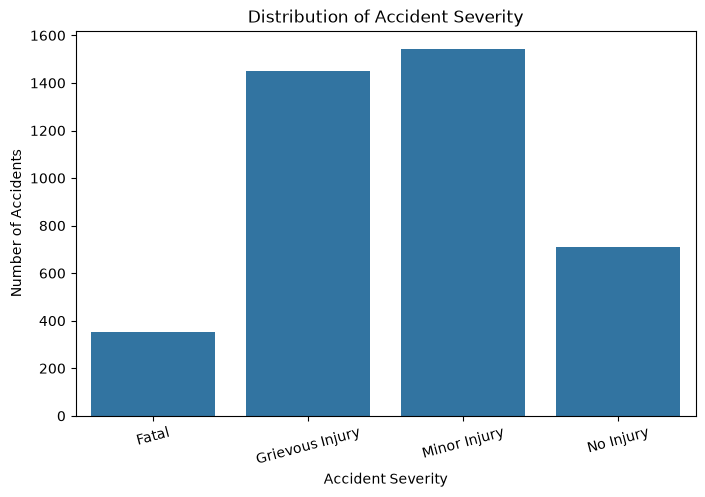

In [31]:
#Accident severity distribution
severity_counts = df["Accident_Severity_C"].value_counts().sort_index()

severity_labels = {
    1: "Fatal",
    2: "Grievous Injury",
    3: "Minor Injury",
    4: "No Injury"
}

plt.figure(figsize=(8, 5))
sns.barplot(
    x=[severity_labels[i] for i in severity_counts.index],
    y=severity_counts.values
)

plt.title("Distribution of Accident Severity")
plt.xlabel("Accident Severity")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=15)
plt.show()

**Observation:**
- Minor injury accidents are the most frequent, followed by grievous injury accidents.
- Fatal accidents have the lowest representation in the dataset.
- The severity classes are imbalanced, which makes class-sensitive evaluation important during model assessment.

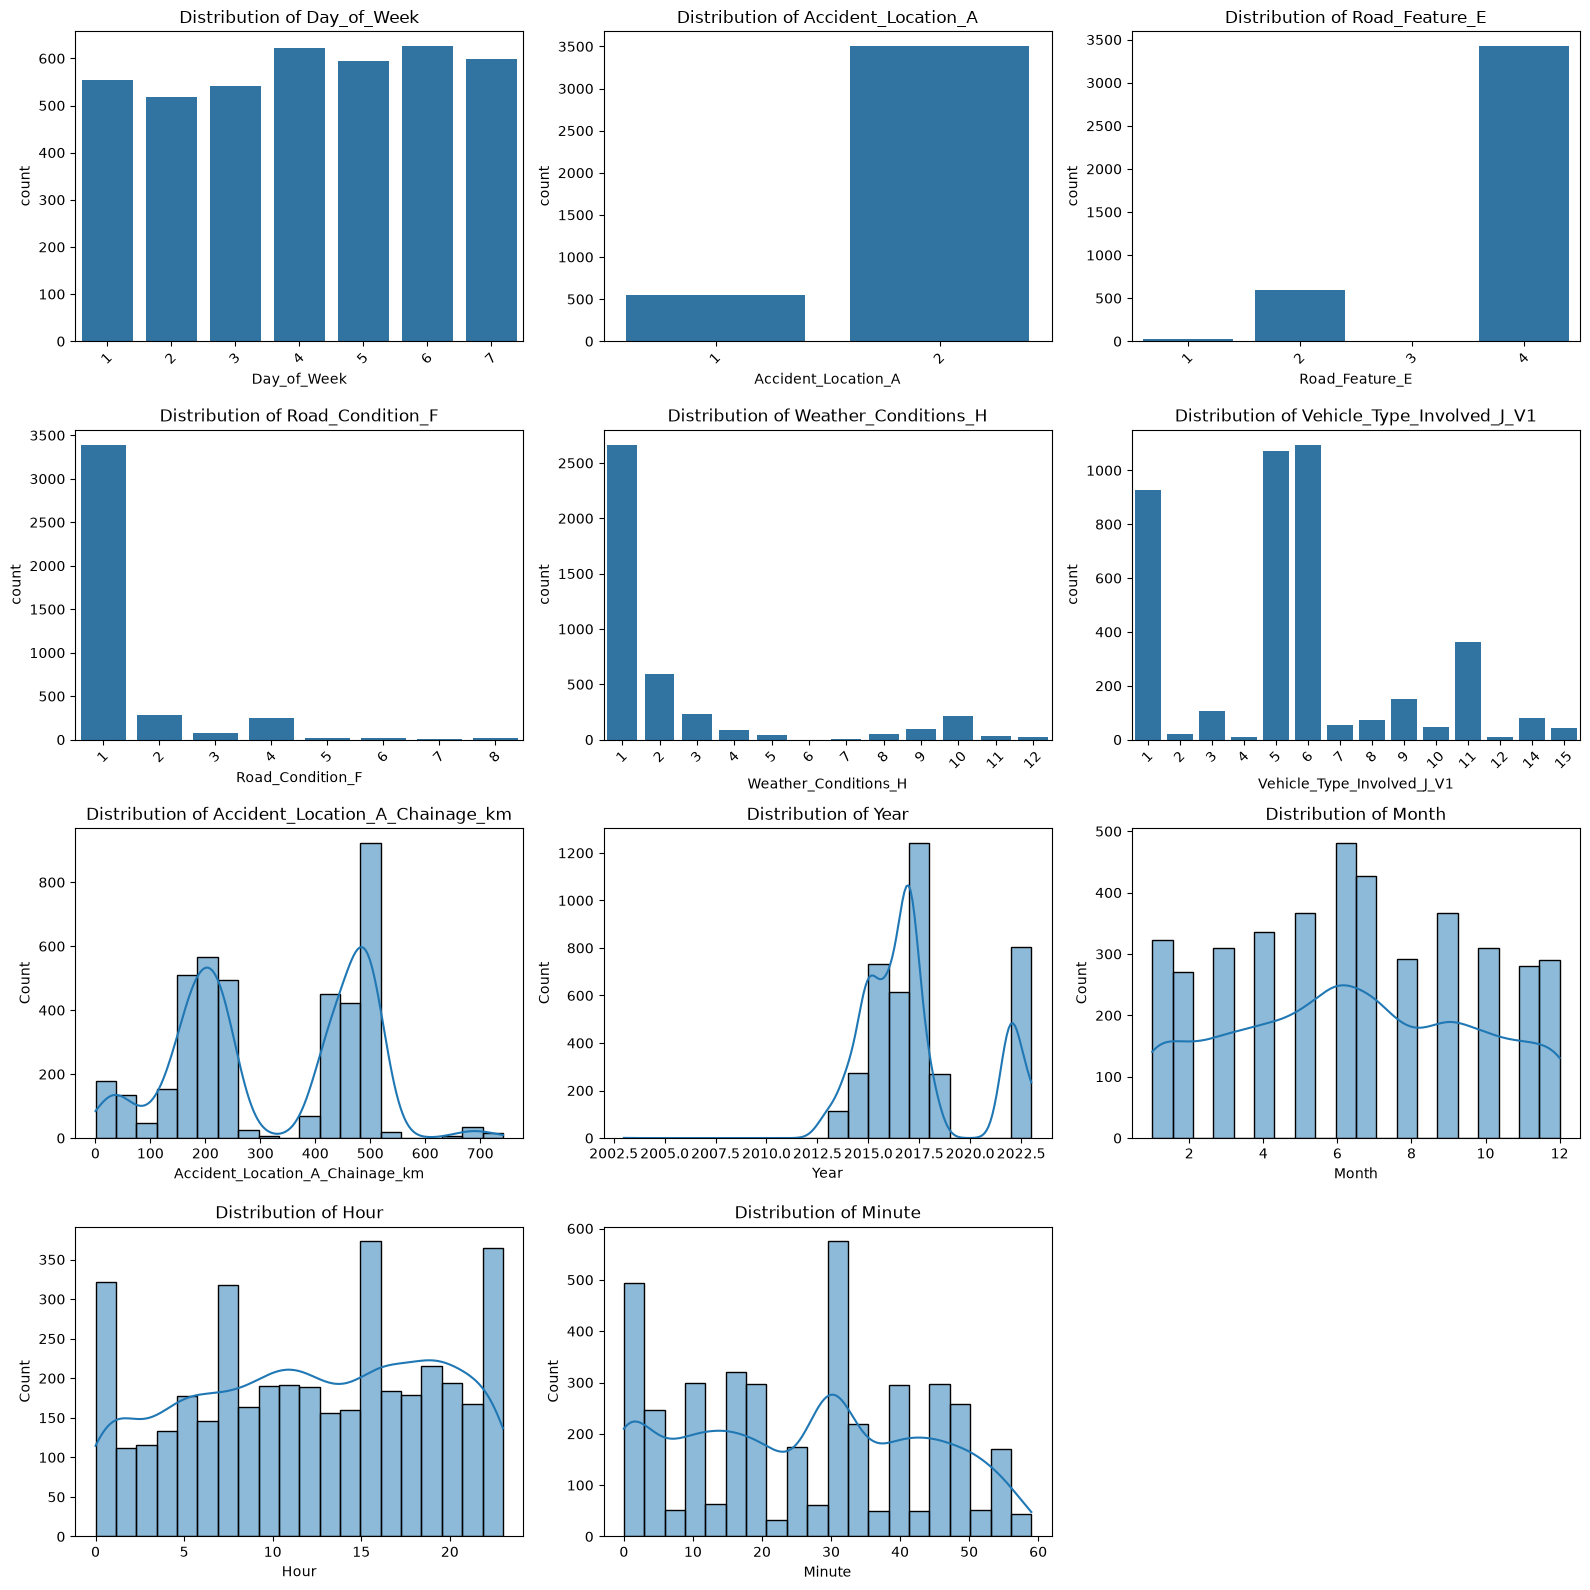

In [32]:
#Correlation Analysis
categorical_eda = categorical_features

numerical_eda = [
    "Accident_Location_A_Chainage_km",
    "Year",
    "Month",
    "Hour",
    "Minute"
]

fig, axes = plt.subplots(4, 3, figsize=(16, 16))
axes = axes.flatten()

for i, col in enumerate(categorical_eda):
    sns.countplot(data=model_df, x=col, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].tick_params(axis="x", rotation=45)

for j, col in enumerate(numerical_eda, start=len(categorical_eda)):
    sns.histplot(data=model_df, x=col, bins=20, kde=True, ax=axes[j])
    axes[j].set_title(f"Distribution of {col}")

for ax in axes[len(categorical_eda) + len(numerical_eda):]:
    ax.remove()

plt.tight_layout()
plt.show()

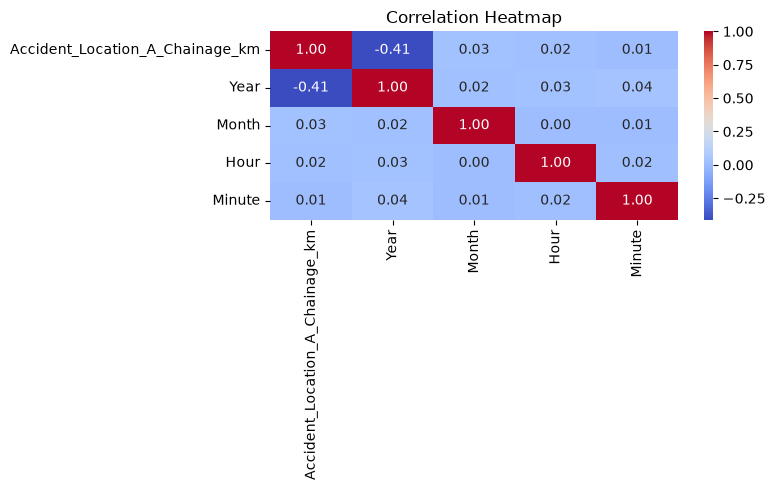

In [33]:
#Correlation Analysis
correlation_features = [
    "Accident_Location_A_Chainage_km",
    "Year",
    "Month",
    "Hour",
    "Minute"
]

plt.figure(figsize=(8, 5))

sns.heatmap(
    model_df[correlation_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

**Conclusion**
- The heatmap shows a moderate negative correlation (-0.41) between road chainage and year, while all other numerical feature pairs have negligible linear correlations.

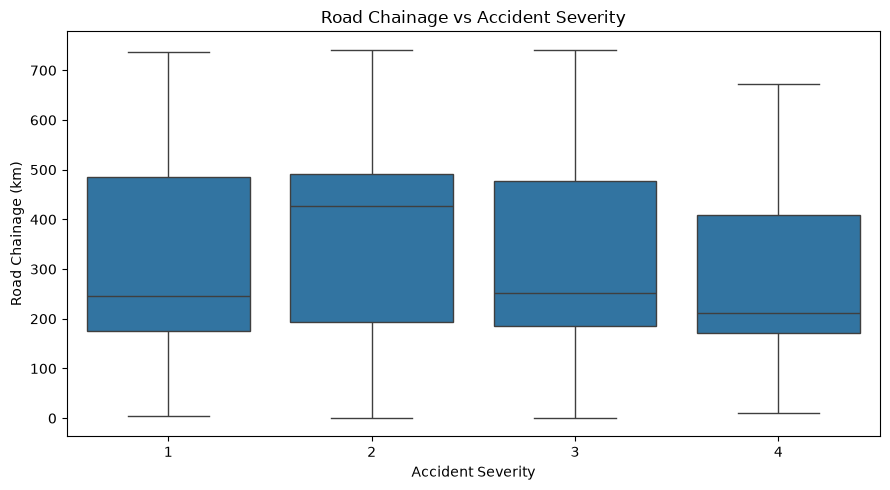

In [34]:
#Feature Relationship Analysis
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=model_df,
    x="Accident_Severity_C",
    y="Accident_Location_A_Chainage_km"
)

plt.title("Road Chainage vs Accident Severity")
plt.xlabel("Accident Severity")
plt.ylabel("Road Chainage (km)")
plt.tight_layout()
plt.show()

**Conclusion** 
- The boxplot shows differences in median road chainage across accident severity classes. However, considerable overlap between their distributions suggests that road chainage alone may not be sufficient to distinguish accident severity.

=================================================================================================================================================================================

## 6. Feature Selection and Data Preprocessing

### 6.1 Separating Features and Target

In [35]:
X = model_df.drop(columns=["Accident_Severity_C"])
y = model_df["Accident_Severity_C"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (4053, 11)
Target: (4053,)


In [36]:
X.columns.tolist()

['Day_of_Week',
 'Accident_Location_A',
 'Accident_Location_A_Chainage_km',
 'Road_Feature_E',
 'Road_Condition_F',
 'Weather_Conditions_H',
 'Vehicle_Type_Involved_J_V1',
 'Year',
 'Month',
 'Hour',
 'Minute']

### 6.2 Train-Test Split

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (3242, 11)
Testing features: (811, 11)
Training target: (3242,)
Testing target: (811,)


### 6.3 Checking Class Distribution

In [38]:
print("Training Set:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTesting Set:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Training Set:
Accident_Severity_C
1    0.087
2    0.358
3    0.380
4    0.175
Name: proportion, dtype: float64

Testing Set:
Accident_Severity_C
1    0.086
2    0.358
3    0.381
4    0.175
Name: proportion, dtype: float64


### 6.4 Building the Preprocessing Pipeline
Now we will:
- Apply One-Hot Encoding to categorical features.
  
  Categorical features will be converted into numerical representations using One-Hot Encoding. This prevents the model from assuming an artificial numerical order between categories.

- Apply StandardScaler to numerical features.
- Fit preprocessing only on training data to prevent data leakage.

In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", StandardScaler(), numerical_features + ["Year", "Month", "Hour", "Minute"])
    ]
)

### 6.5 Applying Preprocessing

Fitting the preprocessing pipeline on training data and transforming both training and testing datasets.

In [40]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (3242, 52)
Processed testing data: (811, 52)


==========================================================================================================================================================

## 7. Model Building and Training 

### 7.1 Logistic Regression

#### 7.1.1 Training

In [41]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_processed, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

#### 7.1.2 Making Prediction

In [42]:
# Make predictions
y_pred_lr = lr_model.predict(X_test_processed)

# Map numerical labels to severity names
severity_mapping = {
    1: "Fatal",
    2: "Grievous Injury",
    3: "Minor Injury",
    4: "No Injury"
}

# Display actual and predicted values
results = pd.DataFrame({
    "Actual Severity": y_test.map(severity_mapping).values,
    "Predicted Severity": pd.Series(y_pred_lr).map(severity_mapping).values
})

print(results.head(10))

   Actual Severity Predicted Severity
0        No Injury       Minor Injury
1        No Injury          No Injury
2  Grievous Injury    Grievous Injury
3  Grievous Injury       Minor Injury
4  Grievous Injury    Grievous Injury
5        No Injury       Minor Injury
6  Grievous Injury       Minor Injury
7        No Injury          No Injury
8  Grievous Injury       Minor Injury
9     Minor Injury       Minor Injury


#### 7.1.3 Model Accuracy

In [43]:
from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 43.16 %


### 7.2 Decision Tree Classifier

#### 7.2.1 Model Training

In [44]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

#### 7.2.2 Making Predictions

In [45]:
y_pred_dt = dt_model.predict(X_test_processed)

severity_mapping = {
    1: "Fatal",
    2: "Grievous Injury",
    3: "Minor Injury",
    4: "No Injury"
}

results_dt = pd.DataFrame({
    "Actual Severity": y_test.map(severity_mapping).values,
    "Predicted Severity": pd.Series(y_pred_dt).map(severity_mapping).values
})

print(results_dt.head(10))

   Actual Severity Predicted Severity
0        No Injury          No Injury
1        No Injury          No Injury
2  Grievous Injury    Grievous Injury
3  Grievous Injury          No Injury
4  Grievous Injury    Grievous Injury
5        No Injury    Grievous Injury
6  Grievous Injury       Minor Injury
7        No Injury              Fatal
8  Grievous Injury       Minor Injury
9     Minor Injury       Minor Injury


#### 7.2.3 Model Accuracy

In [46]:
from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")

Decision Tree Accuracy: 40.32 %


### 7.3 Random Forest Classifier

#### 7.3.1 Model Training

In [47]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

#### 7.3.2 Making Predictions

In [48]:
y_pred_rf = rf_model.predict(X_test_processed)

results_rf = pd.DataFrame({
    "Actual Severity": y_test.map(severity_mapping).values,
    "Predicted Severity": pd.Series(y_pred_rf).map(severity_mapping).values
})

print(results_rf.head(10))

   Actual Severity Predicted Severity
0        No Injury          No Injury
1        No Injury    Grievous Injury
2  Grievous Injury       Minor Injury
3  Grievous Injury          No Injury
4  Grievous Injury    Grievous Injury
5        No Injury       Minor Injury
6  Grievous Injury       Minor Injury
7        No Injury          No Injury
8  Grievous Injury       Minor Injury
9     Minor Injury       Minor Injury


#### 7.3.3 Model Accuracy

In [49]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 45.25 %


=================================================================================================================================================================================================

## 8. Model Evaluation and Comparison

### 8.1 Model Evaluation Metrics

Evaluating the trained models using accuracy, precision, recall, and F1-score.

In [50]:
from sklearn.metrics import classification_report

### 8.2 Classification Report — Logistic Regression

In [51]:
print("Logistic Regression Classification Report:\n")

print(classification_report(
    y_test,
    y_pred_lr,
    labels=[1, 2, 3, 4],
    target_names=["Fatal", "Grievous Injury", "Minor Injury", "No Injury"],
    zero_division=0
))

Logistic Regression Classification Report:

                 precision    recall  f1-score   support

          Fatal       0.00      0.00      0.00        70
Grievous Injury       0.46      0.54      0.50       290
   Minor Injury       0.41      0.52      0.46       309
      No Injury       0.40      0.22      0.28       142

       accuracy                           0.43       811
      macro avg       0.32      0.32      0.31       811
   weighted avg       0.39      0.43      0.40       811



**Observation:** Logistic Regression achieved 43.16% accuracy with a weighted F1-score of 0.40. The model failed to identify Fatal accident cases, indicating difficulty in handling the minority class. Its performance requires further improvement.

### 8.3 Classification Report — Decision Tree

In [52]:
print("Decision Tree Classification Report:\n")

print(classification_report(
    y_test,
    y_pred_dt,
    labels=[1, 2, 3, 4],
    target_names=["Fatal", "Grievous Injury", "Minor Injury", "No Injury"],
    zero_division=0
))

Decision Tree Classification Report:

                 precision    recall  f1-score   support

          Fatal       0.14      0.14      0.14        70
Grievous Injury       0.44      0.44      0.44       290
   Minor Injury       0.46      0.46      0.46       309
      No Injury       0.33      0.33      0.33       142

       accuracy                           0.40       811
      macro avg       0.34      0.34      0.34       811
   weighted avg       0.40      0.40      0.40       811



**Observation:** Decision Tree achieved 40.32% accuracy with a weighted F1-score of 0.40. It identified approximately 14% of Fatal accident cases, showing some improvement over Logistic Regression. However, its overall predictive performance remains limited.

### 8.4 Classification Report — Random Forest

In [53]:
print("Random Forest Classification Report:\n")

print(classification_report(
    y_test,
    y_pred_rf,
    labels=[1, 2, 3, 4],
    target_names=["Fatal", "Grievous Injury", "Minor Injury", "No Injury"],
    zero_division=0
))

Random Forest Classification Report:

                 precision    recall  f1-score   support

          Fatal       0.38      0.04      0.08        70
Grievous Injury       0.46      0.54      0.50       290
   Minor Injury       0.48      0.54      0.51       309
      No Injury       0.36      0.28      0.32       142

       accuracy                           0.45       811
      macro avg       0.42      0.35      0.35       811
   weighted avg       0.44      0.45      0.43       811



**Observation:** Random Forest achieved 45.25% accuracy and a weighted F1-score of 0.43, making it the best-performing model in terms of overall metrics. However, its Fatal accident recall was only 0.04, indicating that it failed to identify most Fatal cases.

### 8.5 Confusion Matrix Visualization

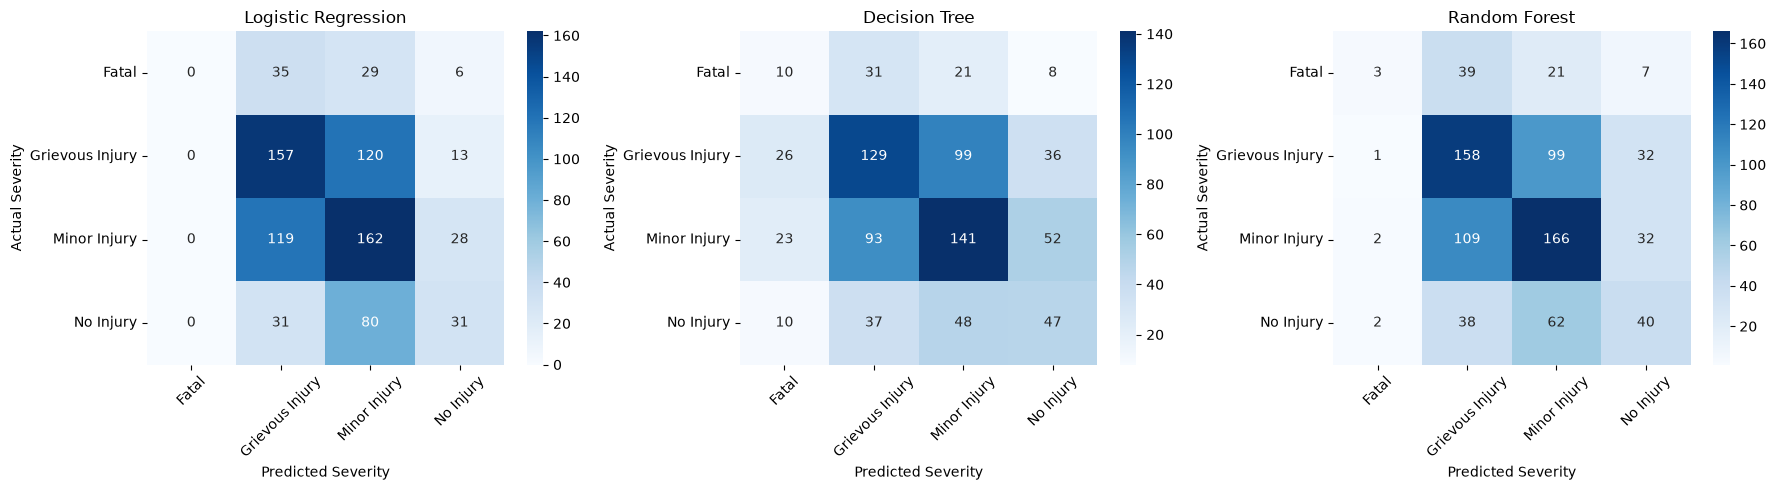

In [54]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

models_predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf
}

severity_labels = [
    "Fatal",
    "Grievous Injury",
    "Minor Injury",
    "No Injury"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, predictions) in zip(axes, models_predictions.items()):
    cm = confusion_matrix(y_test, predictions, labels=[1, 2, 3, 4])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=severity_labels,
        yticklabels=severity_labels,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Severity")
    ax.set_ylabel("Actual Severity")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

**Observation:** Random Forest achieved the highest number of correct predictions (367 out of 811), followed by Logistic Regression (350) and Decision Tree (327). However, Decision Tree identified the highest number of Fatal accident cases (10 out of 70). All three models showed difficulty in correctly classifying Fatal accidents, highlighting the need for further model improvement.

### 8.6 Model Performance Comparison

Comparing the performance of all three classification models using accuracy, precision, recall, and F1-score.

In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision (Weighted)": [
        precision_score(y_test, y_pred_lr, average="weighted", zero_division=0),
        precision_score(y_test, y_pred_dt, average="weighted", zero_division=0),
        precision_score(y_test, y_pred_rf, average="weighted", zero_division=0)
    ],
    "Recall (Weighted)": [
        recall_score(y_test, y_pred_lr, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_dt, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_rf, average="weighted", zero_division=0)
    ],
    "F1-Score (Weighted)": [
        f1_score(y_test, y_pred_lr, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_dt, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_rf, average="weighted", zero_division=0)
    ]
})

print(model_comparison.round(3))

                 Model  Accuracy  Precision (Weighted)  Recall (Weighted)  \
0  Logistic Regression     0.432                 0.392              0.432   
1        Decision Tree     0.403                 0.403              0.403   
2        Random Forest     0.453                 0.441              0.453   

   F1-Score (Weighted)  
0                0.403  
1                0.403  
2                0.433  


**Observation:** Random Forest achieved the highest overall performance with 45.3% accuracy and a weighted F1-score of 0.433. Logistic Regression followed with 43.2% accuracy, while Decision Tree achieved 40.3%. However, Decision Tree performed better in identifying Fatal accident cases, highlighting the importance of evaluating class-wise performance alongside overall metrics.

### 8.7 Model Performance Visualization

Visualizing and comparing the accuracy scores of the three classification models.

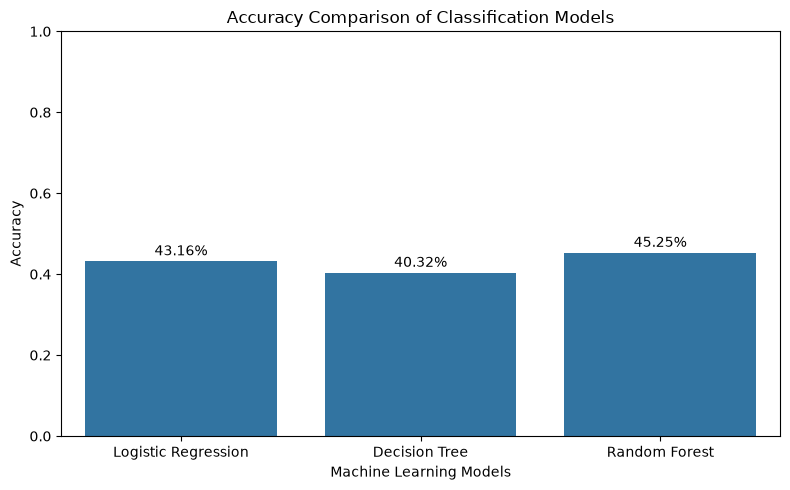

In [56]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

for i, value in enumerate(model_comparison["Accuracy"]):
    plt.text(i, value + 0.015, f"{value:.2%}", ha="center")

plt.tight_layout()
plt.show()

#### 8.7.1 Weighted F1-score Comparison

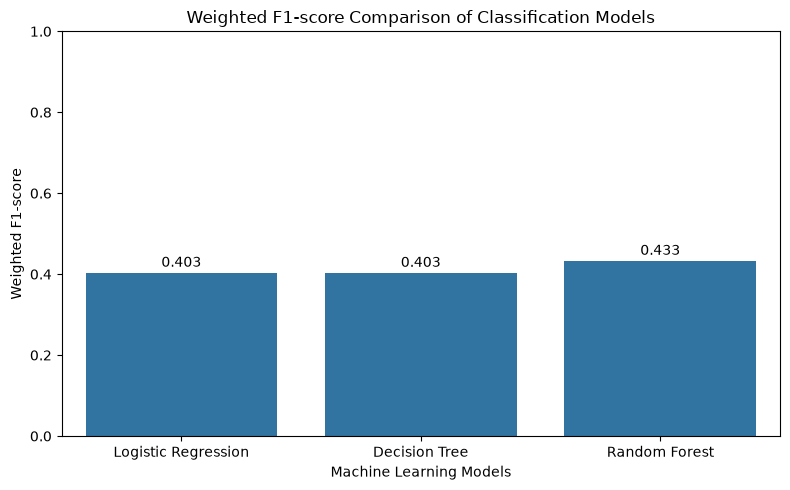

In [57]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="F1-Score (Weighted)"
)

plt.title("Weighted F1-score Comparison of Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Weighted F1-score")
plt.ylim(0, 1)

for i, value in enumerate(model_comparison["F1-Score (Weighted)"]):
    plt.text(i, value + 0.015, f"{value:.3f}", ha="center")

plt.tight_layout()
plt.show()

=================================================================================================================================================================================================

## 9 Feature Importance and Visualization.

### 9.1 Extracting Feature Names
- Retrieving feature names from the preprocessing pipeline for feature importance analysis.

In [58]:
feature_names = preprocessor.get_feature_names_out()

print("Total transformed features:", len(feature_names))
print(feature_names)

Total transformed features: 52
['categorical__Day_of_Week_1' 'categorical__Day_of_Week_2'
 'categorical__Day_of_Week_3' 'categorical__Day_of_Week_4'
 'categorical__Day_of_Week_5' 'categorical__Day_of_Week_6'
 'categorical__Day_of_Week_7' 'categorical__Accident_Location_A_1'
 'categorical__Accident_Location_A_2' 'categorical__Road_Feature_E_1'
 'categorical__Road_Feature_E_2' 'categorical__Road_Feature_E_3'
 'categorical__Road_Feature_E_4' 'categorical__Road_Condition_F_1'
 'categorical__Road_Condition_F_2' 'categorical__Road_Condition_F_3'
 'categorical__Road_Condition_F_4' 'categorical__Road_Condition_F_5'
 'categorical__Road_Condition_F_6' 'categorical__Road_Condition_F_7'
 'categorical__Road_Condition_F_8' 'categorical__Weather_Conditions_H_1'
 'categorical__Weather_Conditions_H_2'
 'categorical__Weather_Conditions_H_3'
 'categorical__Weather_Conditions_H_4'
 'categorical__Weather_Conditions_H_5'
 'categorical__Weather_Conditions_H_6'
 'categorical__Weather_Conditions_H_7'
 'categor

### 9.2 Calculating Feature Importance

Extracting feature importance scores from the trained Decision Tree and Random Forest models.

In [59]:
dt_importances = dt_model.feature_importances_
rf_importances = rf_model.feature_importances_

print("Decision Tree importance scores:", len(dt_importances))
print("Random Forest importance scores:", len(rf_importances))

Decision Tree importance scores: 52
Random Forest importance scores: 52


### 9.3 Creating Feature Importance DataFrames

Combining feature names and importance scores to rank features by their contribution to model predictions.

In [60]:
dt_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": dt_importances
}).sort_values(by="Importance", ascending=False)

rf_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importances
}).sort_values(by="Importance", ascending=False)

print("Decision Tree - Top 10 Features:")
display(dt_feature_importance.head(10))

print("Random Forest - Top 10 Features:")
display(rf_feature_importance.head(10))

Decision Tree - Top 10 Features:


,Feature,Importance
47,numerical__Accident_Location_A_Chainage_km,0.262198
50,numerical__Hour,0.132144
51,numerical__Minute,0.121456
49,numerical__Month,0.109071
48,numerical__Year,0.058761
2,categorical__Day_of_Week_3,0.022449
3,categorical__Day_of_Week_4,0.022081
0,categorical__Day_of_Week_1,0.021151
1,categorical__Day_of_Week_2,0.018227
6,categorical__Day_of_Week_7,0.017688


Random Forest - Top 10 Features:


,Feature,Importance
47,numerical__Accident_Location_A_Chainage_km,0.182302
50,numerical__Hour,0.137745
51,numerical__Minute,0.131543
49,numerical__Month,0.113649
48,numerical__Year,0.068168
3,categorical__Day_of_Week_4,0.021026
5,categorical__Day_of_Week_6,0.020401
4,categorical__Day_of_Week_5,0.020296
2,categorical__Day_of_Week_3,0.019614
6,categorical__Day_of_Week_7,0.019428


### 9.4 Visualizing Feature Importance

Comparing the top 10 important features identified by the Decision Tree and Random Forest models.

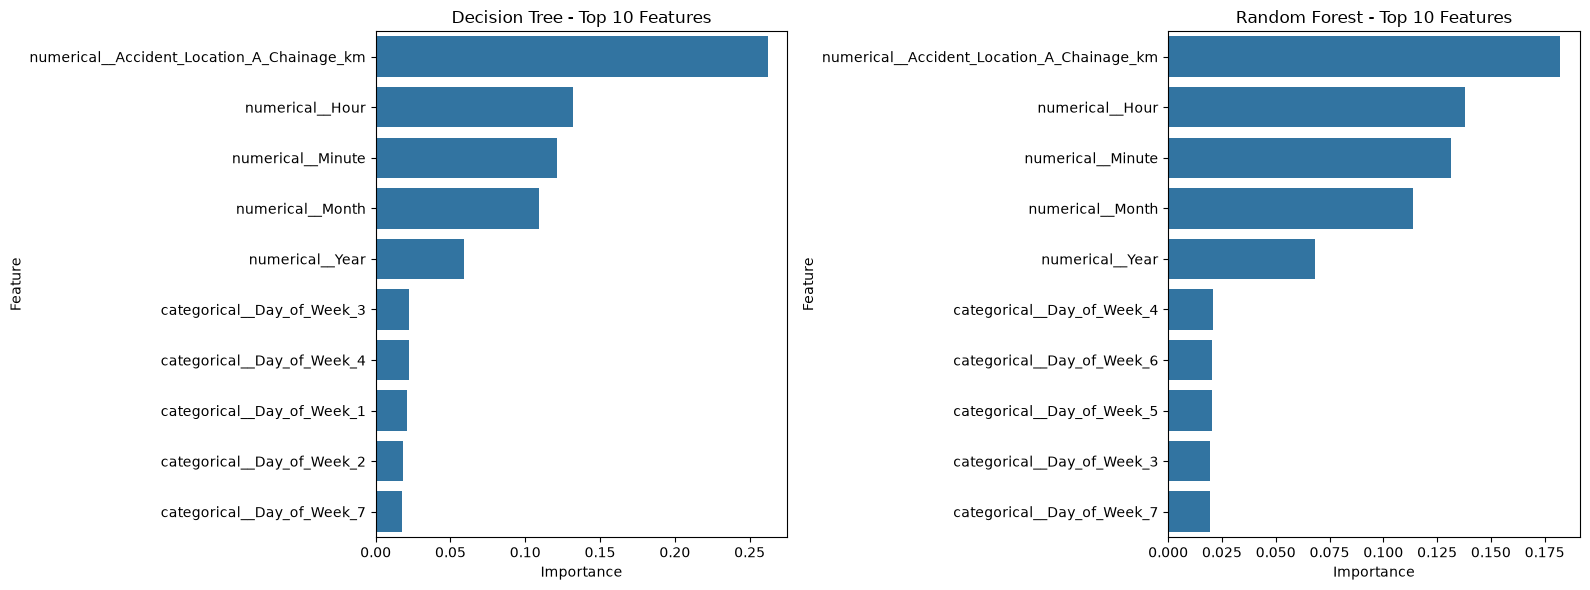

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=dt_feature_importance.head(10),
    x="Importance",
    y="Feature",
    ax=axes[0]
)
axes[0].set_title("Decision Tree - Top 10 Features")

sns.barplot(
    data=rf_feature_importance.head(10),
    x="Importance",
    y="Feature",
    ax=axes[1]
)
axes[1].set_title("Random Forest - Top 10 Features")

plt.tight_layout()
plt.show()

**Observation:**

Both Decision Tree and Random Forest identify road chainage as the most important feature, followed by accident hour, minute, month and year. Day-of-week categories have considerably lower individual importance scores. The similarity in the top five features suggests that both models rely heavily on these numerical features when predicting accident severity.

### 9.5 Overall Feature Importance

Combining the importance scores of encoded categories to evaluate the overall contribution of each original feature.

In [62]:
original_features = categorical_features + numerical_features + [
    "Year", "Month", "Hour", "Minute"
]

def calculate_grouped_importance(importance_scores):
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance_scores
    })

    importance_df["Original Feature"] = importance_df["Feature"].apply(
        lambda name: next(
            feature for feature in original_features
            if name == f"numerical__{feature}"
            or name.startswith(f"categorical__{feature}_")
        )
    )

    return (
        importance_df.groupby("Original Feature")["Importance"]
        .sum()
        .sort_values(ascending=False)
        .reset_index()
    )

dt_grouped_importance = calculate_grouped_importance(dt_importances)
rf_grouped_importance = calculate_grouped_importance(rf_importances)

print("Decision Tree - Overall Feature Importance:")
display(dt_grouped_importance)

print("Random Forest - Overall Feature Importance:")
display(rf_grouped_importance)

Decision Tree - Overall Feature Importance:


,Original Feature,Importance
0,Accident_Location_A_Chainage_km,0.262198
1,Day_of_Week,0.132801
2,Hour,0.132144
3,Minute,0.121456
4,Month,0.109071
5,Vehicle_Type_Involved_J_V1,0.093283
6,Year,0.058761
7,Weather_Conditions_H,0.041158
8,Road_Condition_F,0.028488
9,Road_Feature_E,0.011929


Random Forest - Overall Feature Importance:


,Original Feature,Importance
0,Accident_Location_A_Chainage_km,0.182302
1,Day_of_Week,0.138578
2,Hour,0.137745
3,Minute,0.131543
4,Month,0.113649
5,Vehicle_Type_Involved_J_V1,0.097567
6,Year,0.068168
7,Weather_Conditions_H,0.065163
8,Road_Condition_F,0.030055
9,Road_Feature_E,0.019166


### 9.6 Visualizing Overall Feature Importance

Comparing the overall importance of the original features across Decision Tree and Random Forest models.

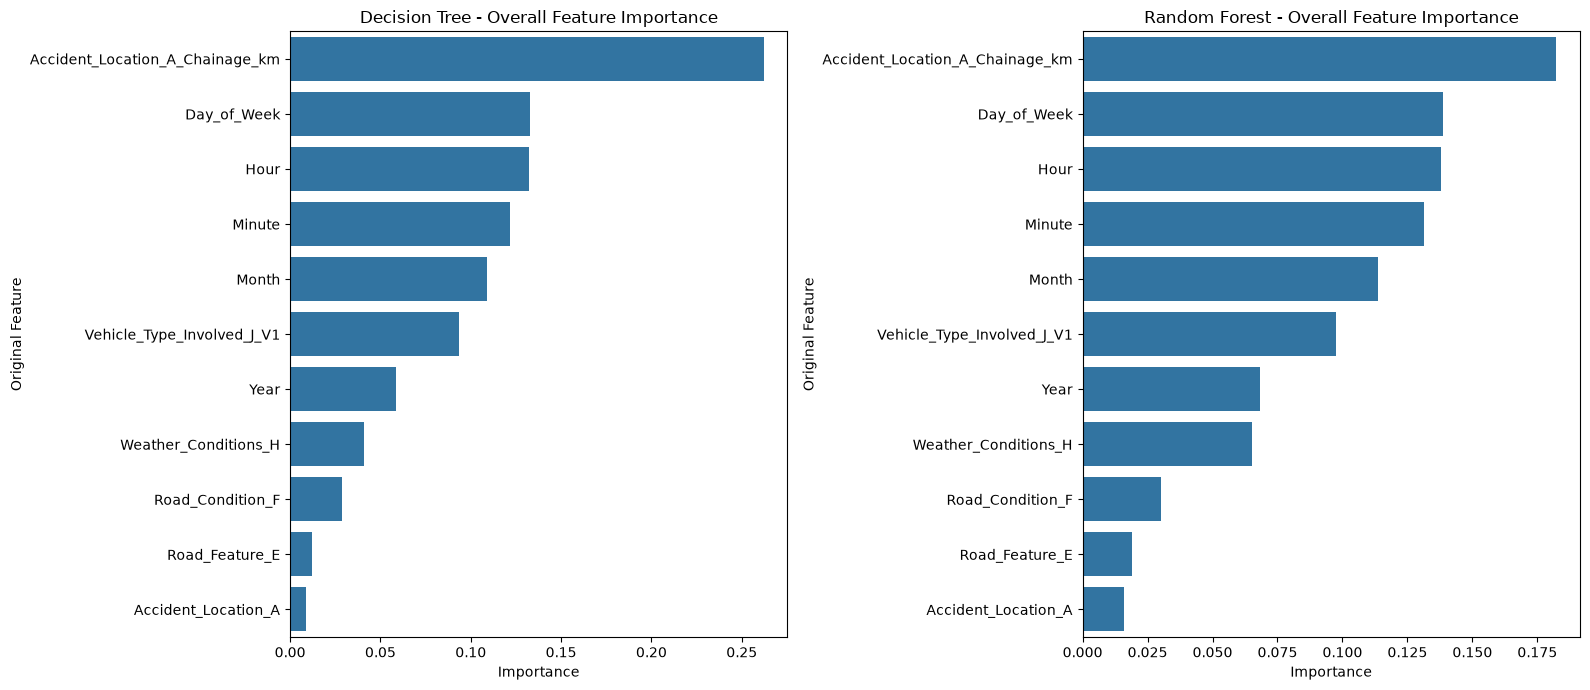

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=dt_grouped_importance,
    x="Importance",
    y="Original Feature",
    ax=axes[0]
)
axes[0].set_title("Decision Tree - Overall Feature Importance")

sns.barplot(
    data=rf_grouped_importance,
    x="Importance",
    y="Original Feature",
    ax=axes[1]
)
axes[1].set_title("Random Forest - Overall Feature Importance")

plt.tight_layout()
plt.show()

=================================================================================================================================================================================================

## 10. Sample Prediction 

### 10.1 Preparing Sample Input

Creating a sample accident record to test the trained classification model.

In [64]:
sample_data = pd.DataFrame([{
    "Day_of_Week": 3,
    "Accident_Location_A": 2,
    "Accident_Location_A_Chainage_km": 125.5,
    "Road_Feature_E": 2,
    "Road_Condition_F": 1,
    "Weather_Conditions_H": 1,
    "Vehicle_Type_Involved_J_V1": 1,
    "Year": 2024,
    "Month": 6,
    "Hour": 14,
    "Minute": 30
}])

display(sample_data)

,Day_of_Week,Accident_Location_A,Accident_Location_A_Chainage_km,Road_Feature_E,Road_Condition_F,Weather_Conditions_H,Vehicle_Type_Involved_J_V1,Year,Month,Hour,Minute
0,3,2,125.5,2,1,1,1,2024,6,14,30


### 10.2 Predicting Accident Severity

Using the trained classification models to predict the severity of the sample accident.

In [65]:
sample_processed = preprocessor.transform(sample_data)

sample_pred_lr = lr_model.predict(sample_processed)[0]
sample_pred_dt = dt_model.predict(sample_processed)[0]
sample_pred_rf = rf_model.predict(sample_processed)[0]

predictions = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Predicted Severity": [
        severity_mapping[sample_pred_lr],
        severity_mapping[sample_pred_dt],
        severity_mapping[sample_pred_rf]
    ]
})

display(predictions)

,Model,Predicted Severity
0,Logistic Regression,No Injury
1,Decision Tree,No Injury
2,Random Forest,Grievous Injury


=================================================================================================================================================================================================

## 11. Model Improvement and Optimization
### 11.1 Handling Class Imbalance

To address the imbalance in accident severity classes, class weighting is applied to give greater importance to minority classes during model training.

In [66]:
# Importing required classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

### 11.2 Training Models with Class Weights

In [67]:
# Logistic Regression with balanced class weights
lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

lr_balanced.fit(X_train_processed, y_train)


# Decision Tree with balanced class weights
dt_balanced = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

dt_balanced.fit(X_train_processed, y_train)


# Random Forest with balanced class weights
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_balanced.fit(X_train_processed, y_train)

print("All balanced models trained successfully.")

All balanced models trained successfully.


### 11.3 Generating Predictions

In [68]:
# Generate predictions using balanced models
y_pred_lr_balanced = lr_balanced.predict(X_test_processed)
y_pred_dt_balanced = dt_balanced.predict(X_test_processed)
y_pred_rf_balanced = rf_balanced.predict(X_test_processed)

print("Predictions generated successfully.")

Predictions generated successfully.


### 11.4 Classification Reports of Balanced Models

In [69]:
from sklearn.metrics import classification_report

print("Logistic Regression - Balanced")
print(classification_report(
    y_test, y_pred_lr_balanced,
    labels=[1, 2, 3, 4],
    target_names=["Fatal", "Grievous Injury", "Minor Injury", "No Injury"],
    zero_division=0
))

print("\nDecision Tree - Balanced")
print(classification_report(
    y_test, y_pred_dt_balanced,
    labels=[1, 2, 3, 4],
    target_names=["Fatal", "Grievous Injury", "Minor Injury", "No Injury"],
    zero_division=0
))

print("\nRandom Forest - Balanced")
print(classification_report(
    y_test, y_pred_rf_balanced,
    labels=[1, 2, 3, 4],
    target_names=["Fatal", "Grievous Injury", "Minor Injury", "No Injury"],
    zero_division=0
))

Logistic Regression - Balanced
                 precision    recall  f1-score   support

          Fatal       0.10      0.19      0.13        70
Grievous Injury       0.50      0.41      0.45       290
   Minor Injury       0.42      0.19      0.27       309
      No Injury       0.29      0.61      0.40       142

       accuracy                           0.35       811
      macro avg       0.33      0.35      0.31       811
   weighted avg       0.40      0.35      0.34       811


Decision Tree - Balanced
                 precision    recall  f1-score   support

          Fatal       0.10      0.09      0.09        70
Grievous Injury       0.48      0.44      0.46       290
   Minor Injury       0.43      0.44      0.43       309
      No Injury       0.30      0.35      0.32       142

       accuracy                           0.39       811
      macro avg       0.33      0.33      0.33       811
   weighted avg       0.39      0.39      0.39       811


Random Forest - Balanced

### 11.5 Performance Comparison: Original vs Balanced Models

In [70]:
from sklearn.metrics import accuracy_score, f1_score, recall_score

model_predictions = {
    "Logistic Regression": y_pred_lr,
    "Logistic Regression (Balanced)": y_pred_lr_balanced,
    "Decision Tree": y_pred_dt,
    "Decision Tree (Balanced)": y_pred_dt_balanced,
    "Random Forest": y_pred_rf,
    "Random Forest (Balanced)": y_pred_rf_balanced
}

comparison_results = []

for model_name, predictions in model_predictions.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Weighted F1": f1_score(y_test, predictions, average="weighted"),
        "Macro F1": f1_score(y_test, predictions, average="macro"),
        "Fatal Recall": recall_score(
            y_test, predictions, labels=[1], average=None
        )[0]
    })

comparison_df = pd.DataFrame(comparison_results)

print(comparison_df.round(3).to_string(index=False))

                         Model  Accuracy  Weighted F1  Macro F1  Fatal Recall
           Logistic Regression     0.432        0.403     0.310         0.000
Logistic Regression (Balanced)     0.345        0.344     0.311         0.186
                 Decision Tree     0.403        0.403     0.344         0.143
      Decision Tree (Balanced)     0.393        0.393     0.326         0.086
                 Random Forest     0.453        0.433     0.349         0.043
      Random Forest (Balanced)     0.470        0.465     0.397         0.086


### 11.6 Model Performance Visualization

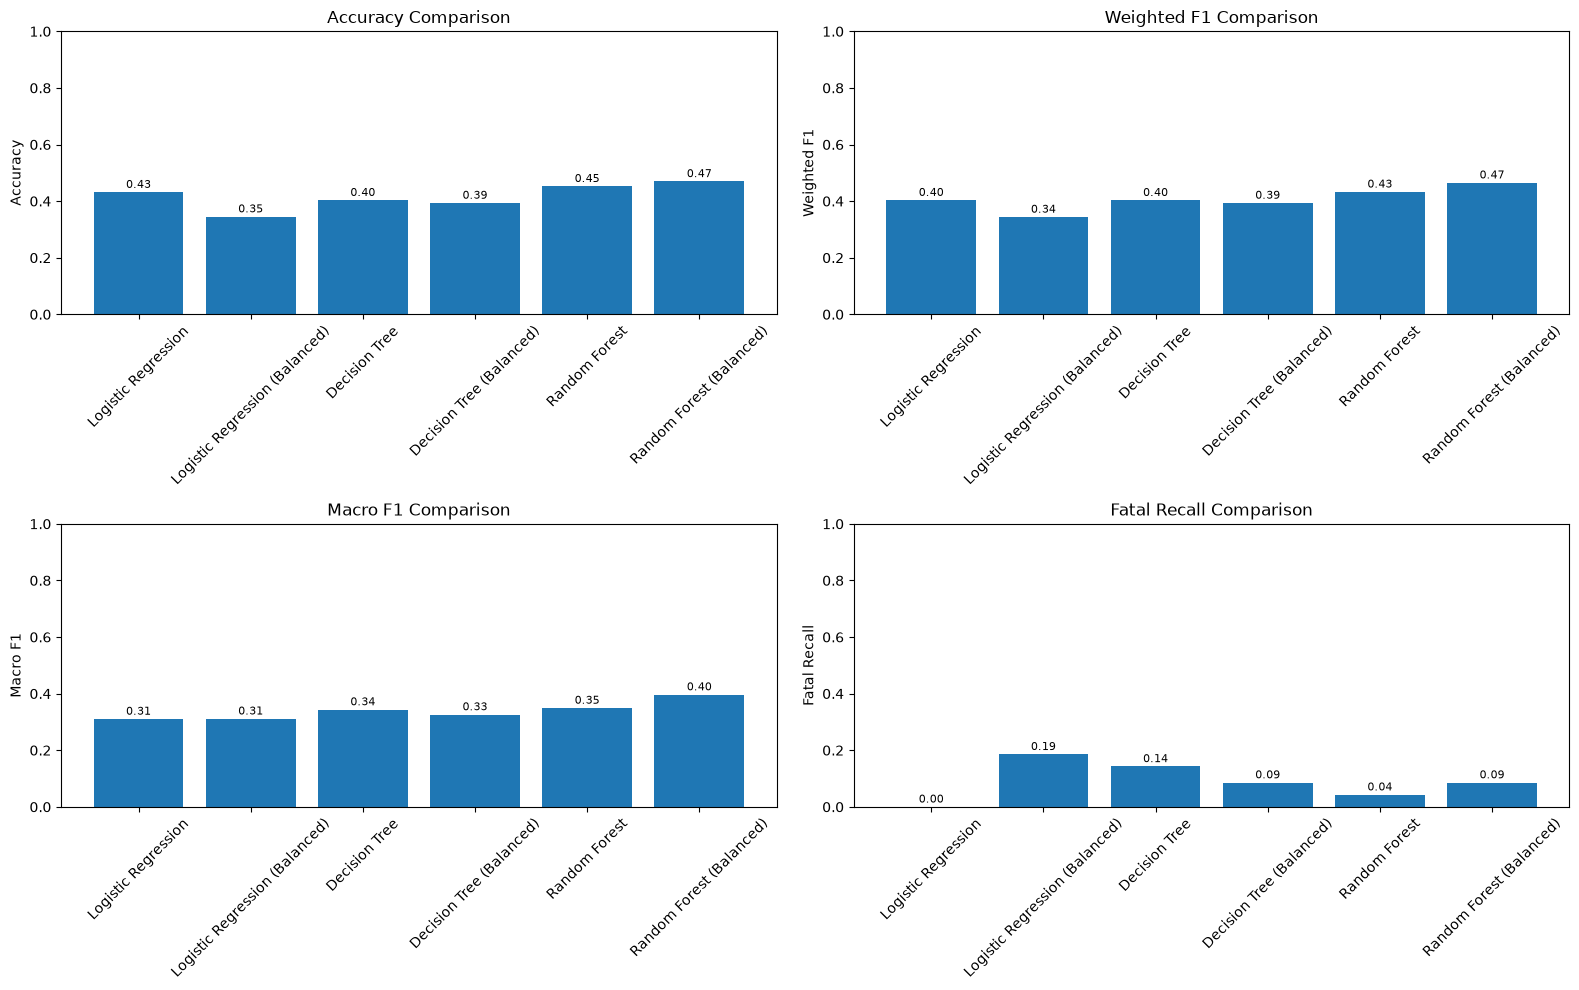

In [71]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Weighted F1", "Macro F1", "Fatal Recall"]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, metric in zip(axes.flatten(), metrics):
    bars = ax.bar(
        comparison_df["Model"],
        comparison_df[metric]
    )

    ax.set_title(f"{metric} Comparison")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=45)

    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.015,
            f"{height:.2f}",
            ha="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()

**Observation:**

- Balanced Random Forest achieved the highest Accuracy (0.47), Weighted F1 (0.47), and Macro F1 (0.40).
- Balanced Logistic Regression achieved the highest Fatal Recall (0.19).
- Class weighting improved the overall performance of Random Forest but reduced the accuracy of Logistic Regression.
- All six models showed limited ability to identify Fatal accidents.

Overall, Balanced Random Forest demonstrated the best overall performance, while Balanced Logistic Regression showed better Fatal accident detection.

=================================================================================================================================================================================================

## 12. Final Model Evaluation and Selection

### 12.1 Final Model Selection

In [72]:
# Selecting the best overall model
final_model = rf_balanced

# Generate final predictions
y_pred_final = final_model.predict(X_test_processed)

print("Selected Model: Balanced Random Forest")
print("Final Accuracy:", round(accuracy_score(y_test, y_pred_final), 3))
print("Final Weighted F1:", round(
    f1_score(y_test, y_pred_final, average="weighted"), 3
))
print("Final Macro F1:", round(
    f1_score(y_test, y_pred_final, average="macro"), 3
))

Selected Model: Balanced Random Forest
Final Accuracy: 0.47
Final Weighted F1: 0.465
Final Macro F1: 0.397


### 12.2 Final Classification Report

In [73]:
print("Final Model: Balanced Random Forest\n")

print(classification_report(
    y_test,
    y_pred_final,
    labels=[1, 2, 3, 4],
    target_names=[
        "Fatal",
        "Grievous Injury",
        "Minor Injury",
        "No Injury"
    ],
    zero_division=0
))

Final Model: Balanced Random Forest

                 precision    recall  f1-score   support

          Fatal       0.13      0.09      0.10        70
Grievous Injury       0.51      0.50      0.51       290
   Minor Injury       0.52      0.49      0.51       309
      No Injury       0.41      0.56      0.47       142

       accuracy                           0.47       811
      macro avg       0.39      0.41      0.40       811
   weighted avg       0.47      0.47      0.47       811



### 12.3 Final Confusion Matrix

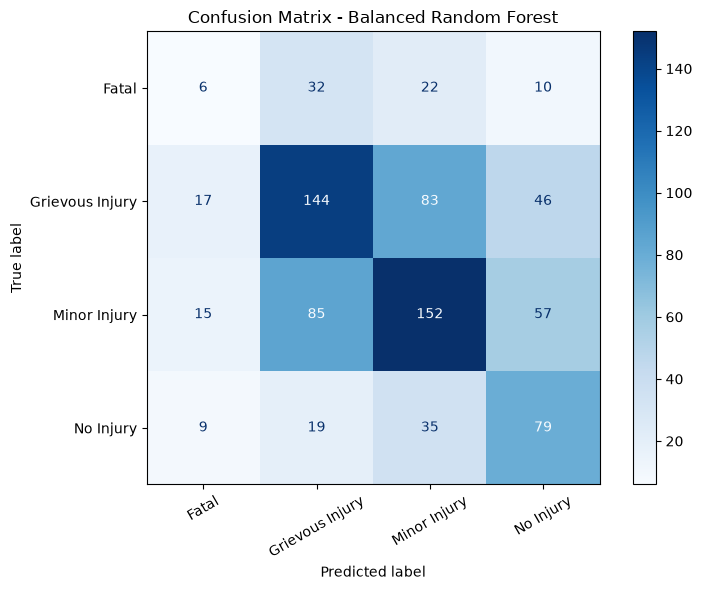

In [74]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_final = confusion_matrix(
    y_test,
    y_pred_final,
    labels=[1, 2, 3, 4]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=[
        "Fatal",
        "Grievous Injury",
        "Minor Injury",
        "No Injury"
    ]
)

fig, ax = plt.subplots(figsize=(8, 6))

display.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Confusion Matrix - Balanced Random Forest")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 12.4 Final Project Conclusion

This project focused on developing a Machine Learning-based system to predict road accident severity using accident-related factors from selected Indian highways.

The dataset was cleaned by removing duplicate records, handling missing values, excluding undocumented features, and extracting useful date and time features. Exploratory Data Analysis was performed to understand accident severity distribution and relationships among the available features.

Three classification algorithms were implemented:
- Logistic Regression
- Decision Tree
- Random Forest

To address class imbalance, balanced versions of all three models were also trained and evaluated.

Among the six model configurations, Balanced Random Forest achieved the best overall performance, with 46.98% accuracy, 0.465 Weighted F1-score, and 0.397 Macro F1-score. Balanced Logistic Regression achieved the highest Fatal accident recall of 18.6%.

Feature importance analysis indicated that road chainage, day of the week, accident hour, and accident month were among the influential features used by the tree-based models.

**Limitations:**

- The dataset contains a limited number of accident records and an imbalanced target distribution.
- Fatal accident classification performance remains poor.
- Some potentially useful features were excluded because their codes were undocumented.
- The model's results are limited to the selected highway dataset and cannot automatically be generalized to all Indian roads.

**Future Scope:**

- Collect larger and more diverse accident datasets.
- Explore advanced techniques for handling class imbalance.
- Perform further feature engineering and hyperparameter optimization.
- Investigate additional classification algorithms and improve Fatal accident detection.

Overall, this project demonstrates the application of Machine Learning techniques for road accident severity prediction and highlights the challenges involved in accurately classifying accident severity, particularly fatal cases.

=================================================================================================================================================================================================